# Phase 5 — Stability-Aware Multi-Step Refinement of PLRNN-SSM

**Course:** Dynamical Systems in Machine Learning  
**Project:** Identifying Nonlinear Dynamical Systems via Generative Recurrent Neural Networks (PLRNN-SSM)  
**Research question:** Can train-only multi-step optimization and stable-trajectory selection improve *independent, autonomous dynamical reconstruction* beyond the initial joint-MAP baseline?

This notebook visualizes an independently executed phase-5 experiment for **van der Pol** and **Lorenz**, fitted with three different PLRNN seeds. It **does not** implement the paper's original Laplace-EM algorithm and must not be described as such. The Phase-1 datasets contain *observation* noise, not the paper's benchmark *process* noise.


## 1. Mathematical idea

The recurrent transition and measurement models remain

$$
\begin{aligned}
 z_{t+1} &= A z_t + W\operatorname{ReLU}(z_t)+h,\\
 x_t &= B\operatorname{ReLU}(z_t),
\end{aligned}
$$

where $A$ is diagonal, $W$ has zero diagonal, and $\operatorname{ReLU}(z)=\max(0,z)$ element-wise.

Our earlier fitting procedure alternated between latent-state estimation and parameter regression. That produced reasonable short-horizon forecasts, but generated trajectories could have the wrong geometry.

**New step:** hold the observation decoder $B$ fixed and optimize the transition parameters $(A,W,h)$ on train-only latent anchors $z_t$ using multi-step rollout:

$$
\mathcal L_{\mathrm{multi}}(\theta)=
\frac{1}{|\mathcal I|H}\sum_{t\in\mathcal I}\sum_{k=1}^H
\frac{\lVert B\operatorname{ReLU}(F_\theta^k(z_t))-x_{t+k}\rVert_2^2}{N}
+\lambda\,\mathcal R(\theta,\theta_0).
$$

Here $F_\theta$ is the PLRNN transition map, $H=10$ is the rollout horizon, and $\theta_0$ denotes the original fitted transition. The regularizer discourages arbitrary parameter drift. Every $x_t$ in the training objective belongs to the **training split only**.


In [2]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Works when the notebook kernel starts either from the repository root
# or from the notebooks/ directory.
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src").exists(), "Open this notebook from your project repository"
sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "results" / "phase5"
RUN_EXPERIMENTS = False  # Switch to True to rerun ALL Phase-5 experiments
print("Repository:", ROOT)
print("Phase-5 results directory:", RESULTS)

Repository: c:\PLRNN-Project
Phase-5 results directory: c:\PLRNN-Project\results\phase5


## 2. Run the experiment or use the included results

The full experiment loads the original PLRNN checkpoints from Phases 3 and 4, performs the multi-step transition refinement, selects an interpolation coefficient using **training observations only**, and then evaluates held-out forecasts and independent long-run trajectories. All previous results and models remain untouched.

For quick validation from the terminal, run `python -m src.training.run_phase5 --quick` (separate outputs). The notebook defaults to the **full included results** without unnecessary retraining.


In [3]:
if RUN_EXPERIMENTS:
    from src.training.run_phase5 import run_phase5
    run_phase5(root=ROOT, quick=False)

results_path = RESULTS / "metrics" / "phase5_records.json"
if not results_path.exists():
    raise FileNotFoundError("Missing Phase-5 outputs: copy ZIP contents into repository root, or rerun the experiment")
with results_path.open(encoding="utf-8") as f:
    experiment = json.load(f)
rows = experiment["records"]
print("Number of fitted checkpoints compared:", len(rows))
print("Training seeds:", experiment["seeds"])
print("Chosen alpha grid:", experiment["alpha_grid"])
print("Independent reference samples per rollout:", experiment["n_independent_reference"])
print("Burn-in steps:", experiment["burn"])

Number of fitted checkpoints compared: 6
Training seeds: [42, 7, 21]
Chosen alpha grid: [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.75, 0.9, 1.0]
Independent reference samples per rollout: 2400
Burn-in steps: 400


## 3. Why not simply optimize multi-step MSE?

Unconstrained multi-step fine-tuning can reduce the forecast error yet destabilize autonomous generation. We therefore interpolate between original and proposed transition parameters:

$$
\theta(\alpha)=(1-\alpha)\theta_0+\alpha\theta_{\rm refined},\qquad\alpha\in[0,1].
$$

Only $A$, $W$, and $h$ change; the observation decoder $B$ is unchanged.

For each candidate $\alpha$, the trained PLRNN runs **freely** from three different *training-only* latent states. A candidate is **rejected if any rollout diverges**. Among stable candidates, the one with the lowest median **training-observation histogram JSD** is selected.

**Important distinction:** this is an internal training-data diagnostic, not a clean validation split. Only *after* $\alpha$ has been selected do we calculate the independent-reference JSD and held-out forecast MSE. The method remains exploratory and does not guarantee correct attractor topology.


In [4]:
column_map = {
    "system": "System", "seed": "Seed", "selected_alpha": "Selected α",
    "before_independent_js_median": "JSD before",
    "after_independent_js_median": "JSD after",
    "before_forecast_mse_h10": "10-step MSE before",
    "after_forecast_mse_h10": "10-step MSE after",
    "before_stable_runs": "Stable runs before",
    "after_stable_runs": "Stable runs after"
}
view = pd.DataFrame(rows)[list(column_map)].rename(columns=column_map)
display(view.round(4))

,System,Seed,Selected α,JSD before,JSD after,10-step MSE before,10-step MSE after,Stable runs before,Stable runs after
0,van_der_pol,42,0.3,0.4313,0.0593,0.1445,0.0923,3,3
1,van_der_pol,7,0.2,0.4996,0.1271,0.1290,0.1102,3,3
2,van_der_pol,21,0.4,0.2018,0.0488,0.1257,0.0880,3,3
3,lorenz,42,0.4,0.4583,0.3940,0.8683,0.6753,3,3
4,lorenz,7,0.0,0.4197,0.4197,0.9980,0.9980,3,3
5,lorenz,21,0.0,0.4218,0.4218,0.9515,0.9515,3,3


## 4. Independent long-run reconstruction

The following Jensen–Shannon divergences compare full **free-running trajectories** with clean, independent ODE simulations generated from different initial states, in a shared standardized observation space. Lower means that the sampled state-space *occupancy* is more similar. JSD is not identical to the paper's normalized KL divergence, and a low JSD alone does **not** prove dynamical or topological equivalence.

There are **three fitted training seeds** and **three initial-state restarts per fitted model**. We report the median JSD of each checkpoint's restarts, not nine statistically independent network fits.


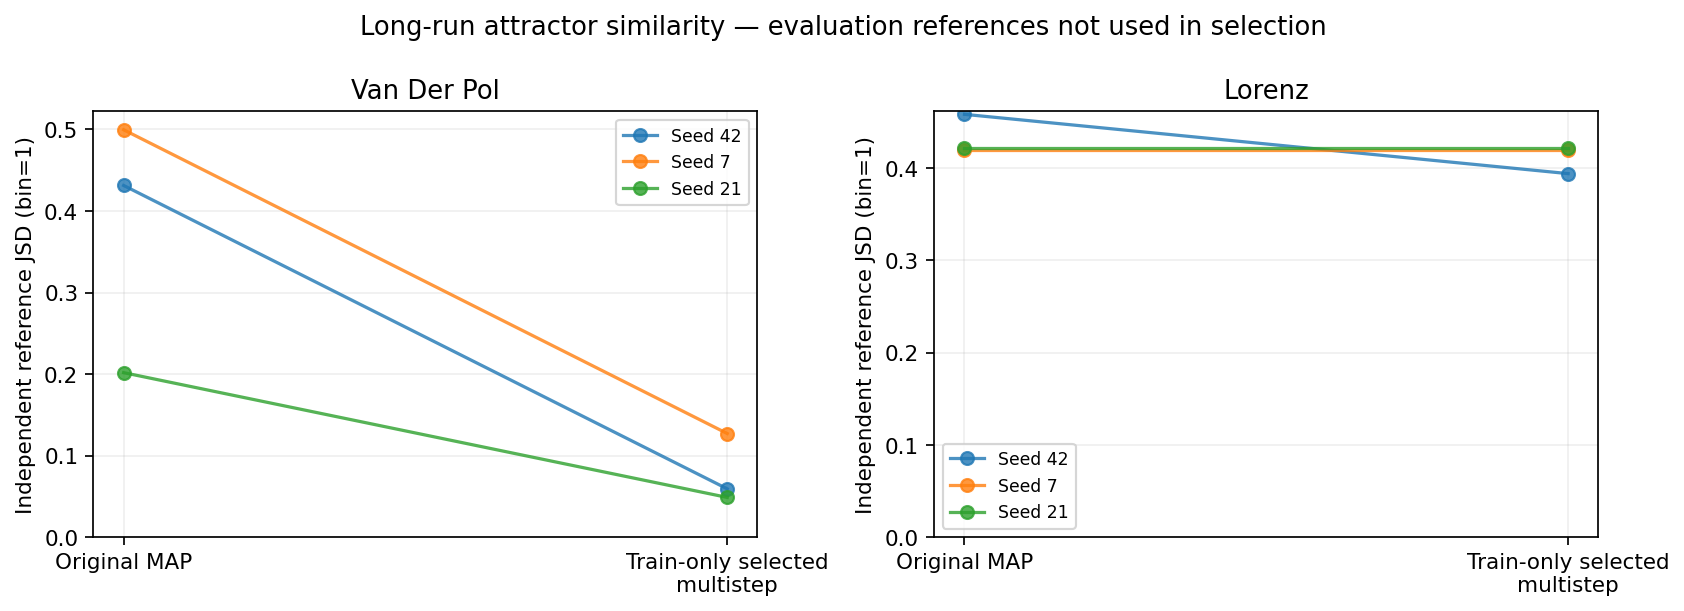

In [5]:
display(Image(filename=str(RESULTS / "figures" / "phase5_independent_js.png")))

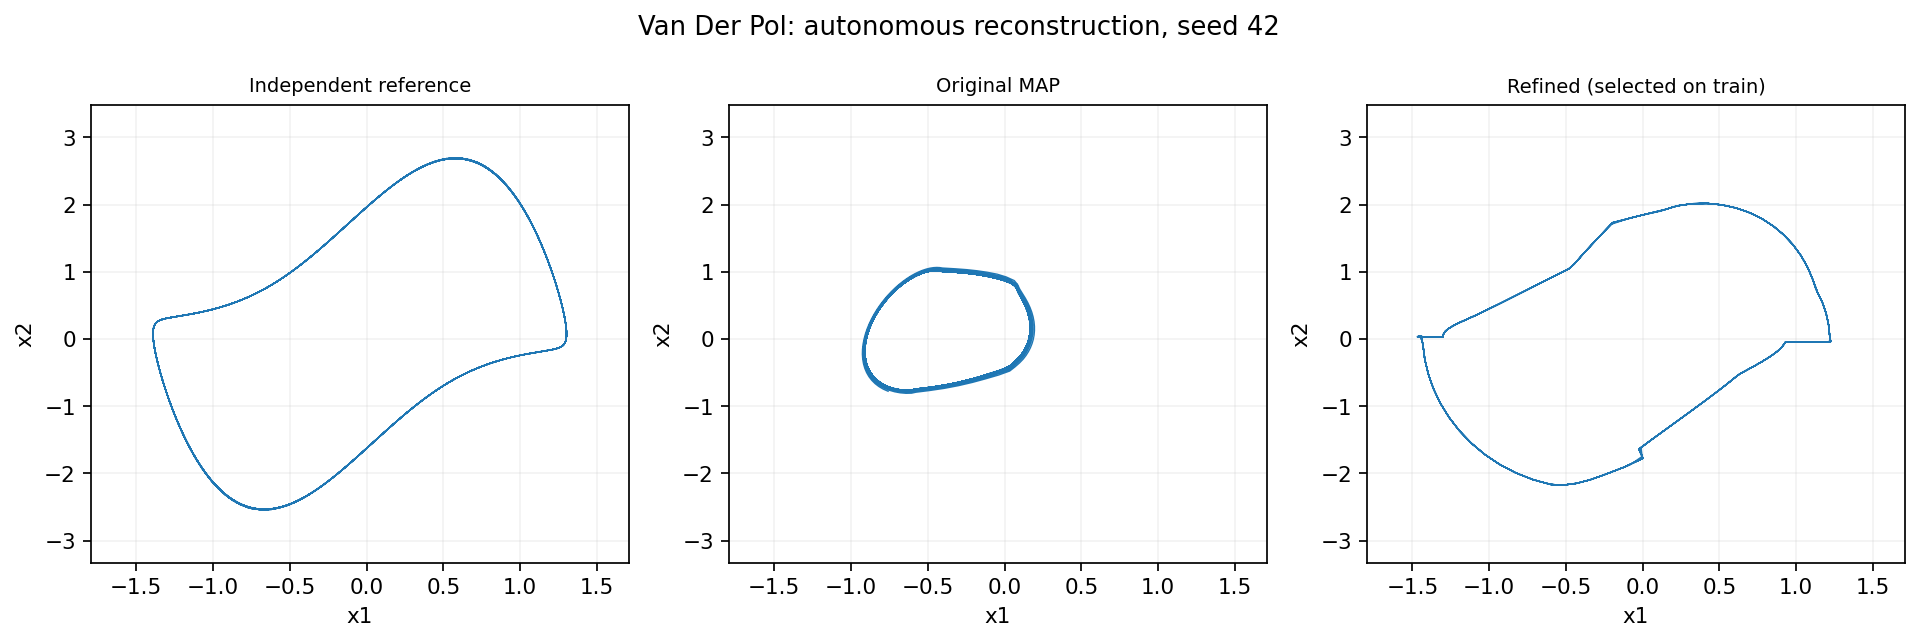

In [6]:
display(Image(filename=str(RESULTS / "figures" / "phase5_van_der_pol_rollouts.png")))

### Interpretation — van der Pol

The original model often learns an undersized, deformed limit cycle. The stability-aware multi-step approach improves the occupancy distribution of its autonomous oscillations on all three tested fitting seeds. In the displayed seed-42 example, the resulting cycle is **closer but not identical** to the reference: the corner transitions, amplitude and shape remain imperfect. This is improved limit-cycle reconstruction, not exact recovery of the underlying ODE.


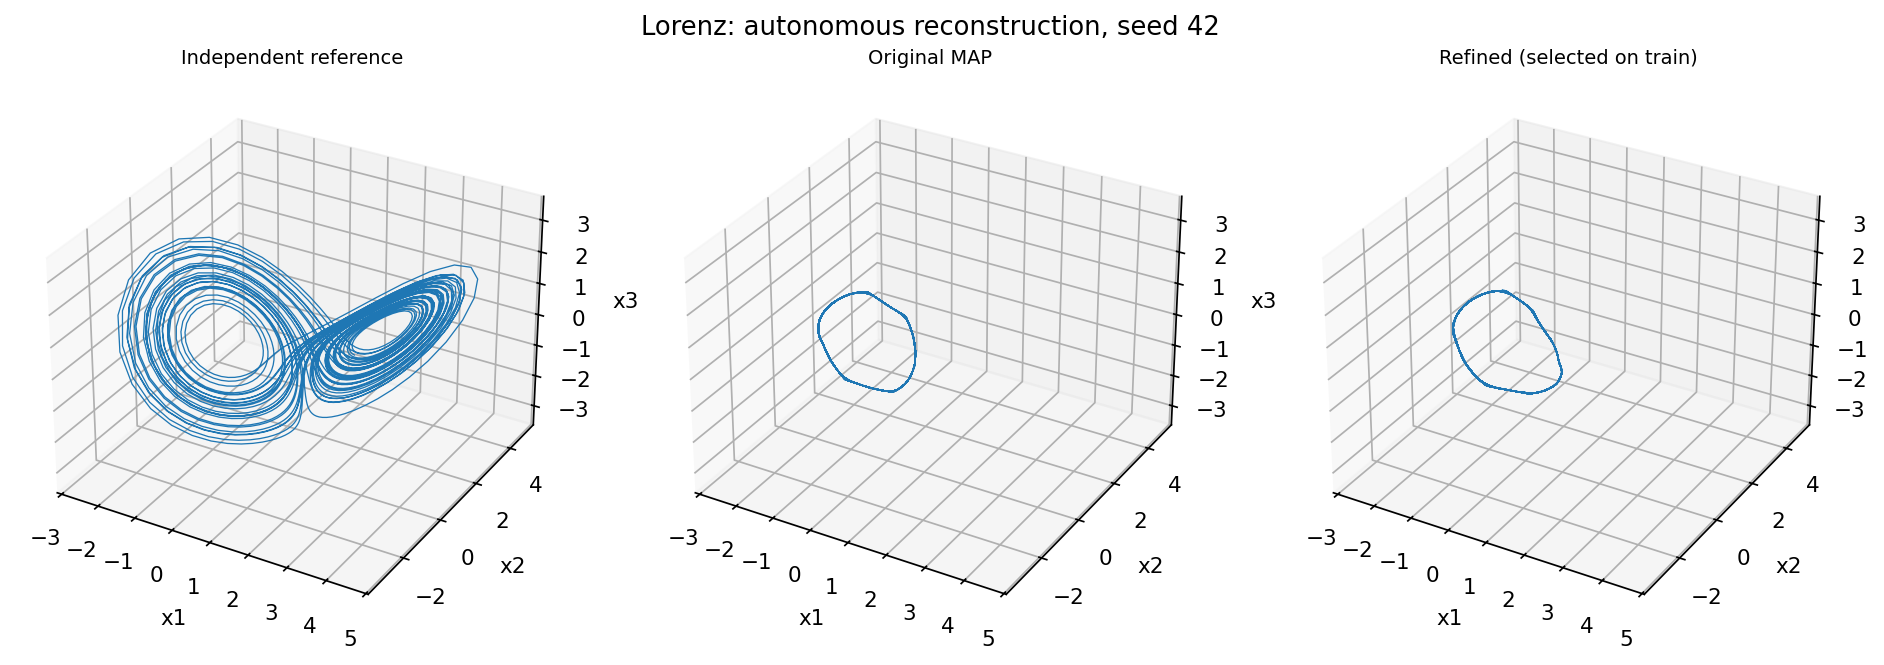

In [7]:
display(Image(filename=str(RESULTS / "figures" / "phase5_lorenz_rollouts.png")))

### Interpretation — Lorenz

The seed-42 JSD decreases modestly, but the generated state-space structure still resembles a simplified loop rather than the reference's two-lobed chaotic attractor. The other two seeds retain their original model parameters under train-only selection. **We have not recovered the Lorenz butterfly or verified true chaotic equivalence.** This is a substantial and scientifically informative limitation.


## 5. Held-out prediction at 10 steps

The test split covers the last 300 samples of the original dataset. The 10-step MSE is calculated **after** the train-only selection. Note that good forecast performance can coexist with poor autonomous attractor reconstruction, especially for chaotic systems.


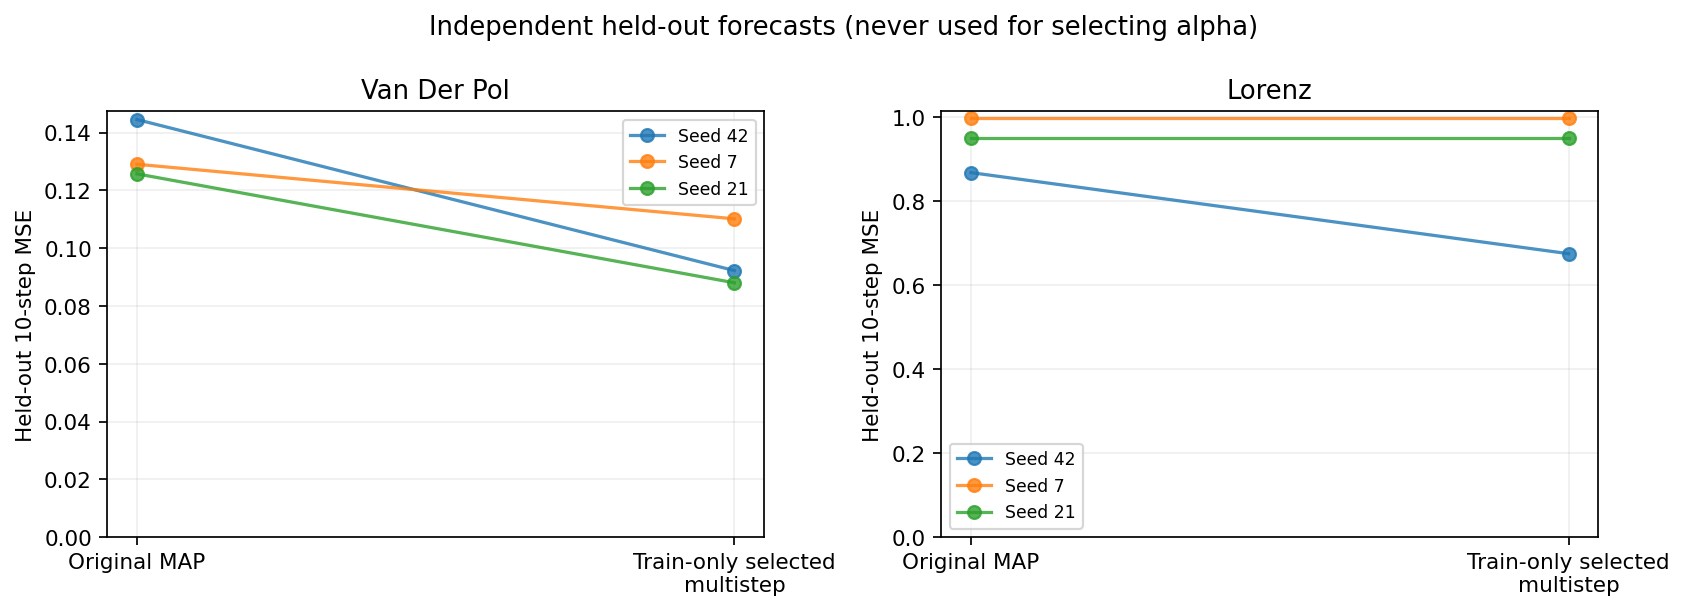

In [8]:
display(Image(filename=str(RESULTS / "figures" / "phase5_heldout_mse.png")))

## 6. Selection diagnostics and failure modes

Each row stores the full interpolation-grid evaluation. Inspect the rejected candidates to see how a nominally better multi-step transition can fail a stability check. The selector never removes failed runs from the record, and never uses the held-out test samples for its decision.


In [9]:
diagnostics = []
for r in rows:
    for candidate in r["selection"]["candidates"]:
        diagnostics.append({
            "system": r["system"], "seed": r["seed"],
            "alpha": candidate["alpha"], "stable": candidate["accepted"],
            "training JSD": candidate["train_js_median"],
            "selected": np.isclose(candidate["alpha"], r["selected_alpha"])
        })
diagn = pd.DataFrame(diagnostics)
display(diagn[(diagn["system"] == "lorenz") & (diagn["seed"] == 42)].round(4))
print("Unstable candidates (all systems and seeds):", int((~diagn["stable"]).sum()))

,system,seed,alpha,stable,training JSD,selected
30,lorenz,42,0.00,True,0.2293,False
31,lorenz,42,0.10,True,0.1907,False
32,lorenz,42,0.20,True,0.1851,False
33,lorenz,42,0.30,True,0.1792,False
34,lorenz,42,0.40,True,0.1730,True
35,lorenz,42,0.50,False,NaN,False
36,lorenz,42,0.60,False,NaN,False
37,lorenz,42,0.75,False,NaN,False
38,lorenz,42,0.90,False,NaN,False
39,lorenz,42,1.00,False,NaN,False


Unstable candidates (all systems and seeds): 28


## 7. Conclusions and limitations

**What we learned:** (i) a multi-step observation objective can improve forecasts; (ii) selecting solely on multi-step error is unsafe because autonomous rollouts may diverge; (iii) free-running train-only occupancy and stability checks can substantially improve the recovered van der Pol limit cycle; and (iv) even these measures do not solve the much harder Lorenz attractor problem with our simplified MAP-PLRNN.

**Limitations to report explicitly:**

- The inference method is alternating joint-MAP, **not** the original Koppe et al. Laplace-EM.
- The alpha selection compares generated samples with **training** observations; it is a heuristic and not independent validation.
- JSD depends on histogram bin widths, the available samples, the scaling, and the selected initial states.
- All measurements are exploratory with just three fitted training seeds; no confidence intervals or significance tests are claimed.
- The original benchmark data include Gaussian **observation noise**, while the paper also studies **process noise**.
- Neither low histogram divergence nor improved 10-step MSE guarantees the correct Lyapunov exponent or chaotic attractor.

**Next step:** add a hemodynamic-response (HRF) observation layer and synthetic BOLD measurements as a controlled bridge toward fMRI, retaining the same clear boundary between synthetic and real human recordings.
